<a href="https://colab.research.google.com/github/dixtcode-hub/BTNG_DATA_SCIENCE_TA/blob/main/BTNG_DataScience_Prediksi_Performa_Akademik.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TUGAS AKHIR BTNG DATA SCIENCE
## Prediksi Performa Akademik Mahasiswa Informatika
**Struktur pengerjaan: Week 1 – Week 3**

**Dataset:** `student_performance_informatika.csv`  
**Target yang tersedia:** `passed` (klasifikasi biner)

# INISIALISASI, LOAD DATASET, DAN EDA AWAL

## Tujuan
1. Import library.
2. Upload dan membaca file CSV.
3. Memeriksa dimensi, struktur, tipe data, statistik, missing values, duplikat, nilai unik, nilai mencurigakan, dan outlier.
4. Memvisualisasikan distribusi target dan fitur awal.

In [1]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Library berhasil diimpor.")

Library berhasil diimpor.


In [2]:
# Upload dataset
uploaded = files.upload()

# Gunakan nama file yang diunggah
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Nama file:", file_name)
print("Dimensi dataset:", df.shape)
display(df.head())

Saving student_performance_informatika.csv to student_performance_informatika.csv
Nama file: student_performance_informatika.csv
Dimensi dataset: (800, 14)


,attendance_pct,study_hours_week,sleep_hours,screen_time_hours,parttime_hours_week,commute_minutes,internet_quality,org_activity,hs_math_score,assignment_avg,quiz_avg,midterm_score,Year,passed
0,75.2,8.9,6.8,1.0,0,28,4,2,82,74.0,63.5,76.6,2024,1
1,74.3,6.7,4.2,1.7,0,37,3,0,100,64.2,62.4,63.1,2024,1
2,84.1,11.9,7.7,2.2,0,13,4,2,72,73.2,71.1,41.3,2024,1
3,74.4,4.8,6.6,3.7,6,15,3,1,61,42.3,49.5,76.0,2024,0
4,100.0,7.5,6.4,2.2,0,30,4,2,70,66.7,51.9,71.4,2024,1


In [3]:
# Melihat data awal dan akhir
print("Lima baris pertama:")
display(df.head())

print("Lima baris terakhir:")
display(df.tail())

Lima baris pertama:


,attendance_pct,study_hours_week,sleep_hours,screen_time_hours,parttime_hours_week,commute_minutes,internet_quality,org_activity,hs_math_score,assignment_avg,quiz_avg,midterm_score,Year,passed
0,75.2,8.9,6.8,1.0,0,28,4,2,82,74.0,63.5,76.6,2024,1
1,74.3,6.7,4.2,1.7,0,37,3,0,100,64.2,62.4,63.1,2024,1
2,84.1,11.9,7.7,2.2,0,13,4,2,72,73.2,71.1,41.3,2024,1
3,74.4,4.8,6.6,3.7,6,15,3,1,61,42.3,49.5,76.0,2024,0
4,100.0,7.5,6.4,2.2,0,30,4,2,70,66.7,51.9,71.4,2024,1


Lima baris terakhir:


,attendance_pct,study_hours_week,sleep_hours,screen_time_hours,parttime_hours_week,commute_minutes,internet_quality,org_activity,hs_math_score,assignment_avg,quiz_avg,midterm_score,Year,passed
795,71.6,5.9,8.8,2.0,0,10,3,1,73,59.8,45.8,72.4,2018,0
796,81.8,4.3,7.1,6.5,0,8,3,1,54,43.7,36.2,55.7,2018,0
797,94.5,6.4,6.0,5.8,11,24,4,1,66,64.4,60.5,71.2,2018,1
798,85.0,2.2,6.1,3.8,0,23,3,0,75,68.6,69.2,80.9,2018,1
799,79.9,4.4,7.2,4.3,0,31,2,1,73,58.7,39.4,65.3,2018,0


In [4]:
# Struktur dan tipe data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   attendance_pct       800 non-null    float64
 1   study_hours_week     800 non-null    float64
 2   sleep_hours          800 non-null    float64
 3   screen_time_hours    800 non-null    float64
 4   parttime_hours_week  800 non-null    int64  
 5   commute_minutes      800 non-null    int64  
 6   internet_quality     800 non-null    int64  
 7   org_activity         800 non-null    int64  
 8   hs_math_score        800 non-null    int64  
 9   assignment_avg       800 non-null    float64
 10  quiz_avg             800 non-null    float64
 11  midterm_score        800 non-null    float64
 12  Year                 800 non-null    int64  
 13  passed               800 non-null    int64  
dtypes: float64(7), int64(7)
memory usage: 87.6 KB


In [5]:
# Statistik deskriptif
display(df.describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
attendance_pct,800.0,84.613250,10.269008,54.8,77.25,84.70,92.800,100.0
study_hours_week,800.0,6.554125,3.871608,0.8,3.70,5.75,8.325,21.9
sleep_hours,800.0,6.396875,1.086798,3.4,5.60,6.40,7.100,9.9
screen_time_hours,800.0,4.055750,2.159977,1.0,2.40,3.70,5.300,13.5
parttime_hours_week,800.0,5.090000,8.785977,0.0,0.00,0.00,8.250,29.0
commute_minutes,800.0,30.398750,19.174249,2.0,17.00,26.00,40.000,136.0
internet_quality,800.0,3.312500,0.931896,1.0,3.00,3.00,4.000,5.0
org_activity,800.0,0.903750,0.907202,0.0,0.00,1.00,1.000,3.0
hs_math_score,800.0,72.720000,11.293517,35.0,65.00,73.00,80.000,100.0
assignment_avg,800.0,67.740875,10.635872,40.3,60.10,67.40,74.325,100.0


Missing values per kolom:


,jumlah_missing
attendance_pct,0
study_hours_week,0
sleep_hours,0
screen_time_hours,0
parttime_hours_week,0
commute_minutes,0
internet_quality,0
org_activity,0
hs_math_score,0
assignment_avg,0


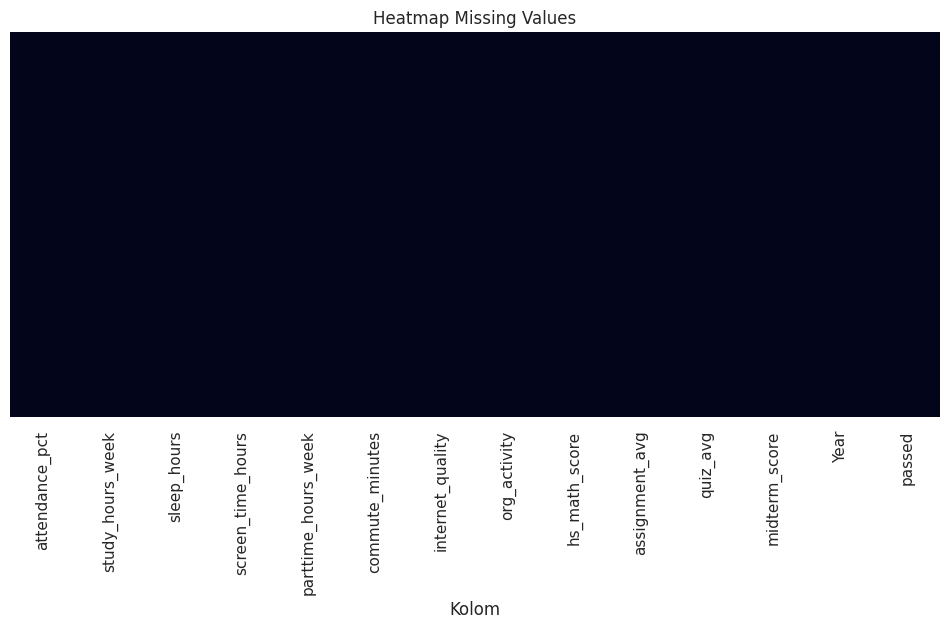

In [6]:
# Missing values
print("Missing values per kolom:")
display(df.isnull().sum().to_frame("jumlah_missing"))

plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Heatmap Missing Values")
plt.xlabel("Kolom")
plt.show()

In [7]:
# Data duplikat
print("Jumlah baris duplikat:", df.duplicated().sum())

Jumlah baris duplikat: 0


In [8]:
# Nilai unik tiap kolom
for col in df.columns:
    print(f"\nKolom: {col}")
    print("Jumlah nilai unik:", df[col].nunique(dropna=False))
    print("Contoh nilai:", df[col].drop_duplicates().head(15).tolist())


Kolom: attendance_pct
Jumlah nilai unik: 317
Contoh nilai: [75.2, 74.3, 84.1, 74.4, 100.0, 95.8, 80.3, 80.8, 73.6, 76.4, 95.7, 80.2, 89.2, 75.6, 74.6]

Kolom: study_hours_week
Jumlah nilai unik: 161
Contoh nilai: [8.9, 6.7, 11.9, 4.8, 7.5, 5.4, 5.3, 10.9, 5.6, 8.1, 6.0, 4.9, 10.3, 10.0, 7.0]

Kolom: sleep_hours
Jumlah nilai unik: 58
Contoh nilai: [6.8, 4.2, 7.7, 6.6, 6.4, 6.3, 5.5, 5.0, 4.1, 7.5, 7.2, 5.2, 3.4, 6.0, 6.1]

Kolom: screen_time_hours
Jumlah nilai unik: 94
Contoh nilai: [1.0, 1.7, 2.2, 3.7, 4.9, 3.8, 3.2, 6.0, 1.4, 3.1, 1.9, 1.3, 5.1, 4.3, 5.4]

Kolom: parttime_hours_week
Jumlah nilai unik: 26
Contoh nilai: [0, 6, 7, 19, 25, 28, 18, 16, 12, 21, 14, 17, 11, 24, 26]

Kolom: commute_minutes
Jumlah nilai unik: 88
Contoh nilai: [28, 37, 13, 15, 30, 36, 18, 29, 50, 8, 63, 19, 20, 17, 23]

Kolom: internet_quality
Jumlah nilai unik: 5
Contoh nilai: [4, 3, 2, 5, 1]

Kolom: org_activity
Jumlah nilai unik: 4
Contoh nilai: [2, 0, 1, 3]

Kolom: hs_math_score
Jumlah nilai unik: 60
Conto

In [9]:
# Periksa target dan nilai yang mencurigakan
target_col = "passed"

if target_col not in df.columns:
    raise ValueError(f"Kolom target '{target_col}' tidak ditemukan. Periksa nama kolom dataset.")

print("Distribusi target:")
display(df[target_col].value_counts(dropna=False).to_frame("jumlah"))
print("\nProporsi target (%):")
display((df[target_col].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame("persentase"))

suspects = ["?", "??", "NA", "N/A", "na", "None", "null", "Unknown", "UNK", "-", "--", " "]
for col in df.columns:
    count = df[col].astype(str).str.strip().isin(suspects).sum()
    if count:
        print(f"Nilai mencurigakan pada {col}: {count}")

Distribusi target:


,jumlah
passed,
1,460
0,340



Proporsi target (%):


,persentase
passed,
1,57.5
0,42.5


In [10]:
# Identifikasi fitur numerik dan kategorikal
num_cols_initial = df.select_dtypes(include=np.number).columns.tolist()
if target_col in num_cols_initial:
    num_cols_initial.remove(target_col)
cat_cols_initial = df.select_dtypes(exclude=np.number).columns.tolist()

print("Fitur numerik:", num_cols_initial)
print("Fitur kategorikal:", cat_cols_initial)

Fitur numerik: ['attendance_pct', 'study_hours_week', 'sleep_hours', 'screen_time_hours', 'parttime_hours_week', 'commute_minutes', 'internet_quality', 'org_activity', 'hs_math_score', 'assignment_avg', 'quiz_avg', 'midterm_score', 'Year']
Fitur kategorikal: []


In [11]:
# Pemeriksaan kandidat outlier dengan metode IQR
# Ini hanya mendeteksi kandidat; tidak langsung menghapus data.
for col in num_cols_initial:
    series = pd.to_numeric(df[col], errors="coerce").dropna()
    if series.empty:
        continue
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((series < lower) | (series > upper)).sum()
    print(f"{col}: {n_outliers} kandidat outlier (batas {lower:.2f} sampai {upper:.2f})")

attendance_pct: 0 kandidat outlier (batas 53.93 sampai 116.12)
study_hours_week: 36 kandidat outlier (batas -3.24 sampai 15.26)
sleep_hours: 1 kandidat outlier (batas 3.35 sampai 9.35)
screen_time_hours: 15 kandidat outlier (batas -1.95 sampai 9.65)
parttime_hours_week: 88 kandidat outlier (batas -12.38 sampai 20.62)
commute_minutes: 24 kandidat outlier (batas -17.50 sampai 74.50)
internet_quality: 15 kandidat outlier (batas 1.50 sampai 5.50)
org_activity: 48 kandidat outlier (batas -1.50 sampai 2.50)
hs_math_score: 3 kandidat outlier (batas 42.50 sampai 102.50)
assignment_avg: 4 kandidat outlier (batas 38.76 sampai 95.66)
quiz_avg: 5 kandidat outlier (batas 29.41 sampai 93.91)
midterm_score: 3 kandidat outlier (batas 33.41 sampai 94.71)
Year: 0 kandidat outlier (batas 2013.00 sampai 2029.00)


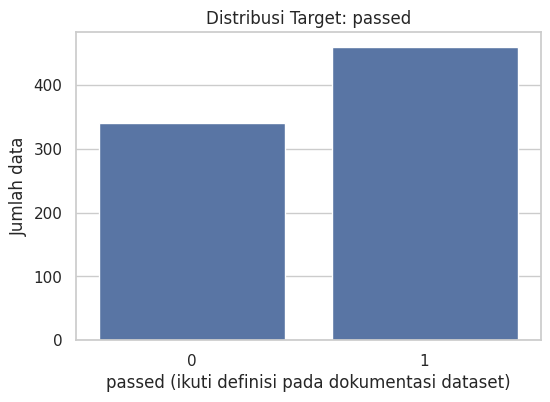

In [12]:
# Distribusi target
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=target_col)
plt.title("Distribusi Target: passed")
plt.xlabel("passed (ikuti definisi pada dokumentasi dataset)")
plt.ylabel("Jumlah data")
plt.show()

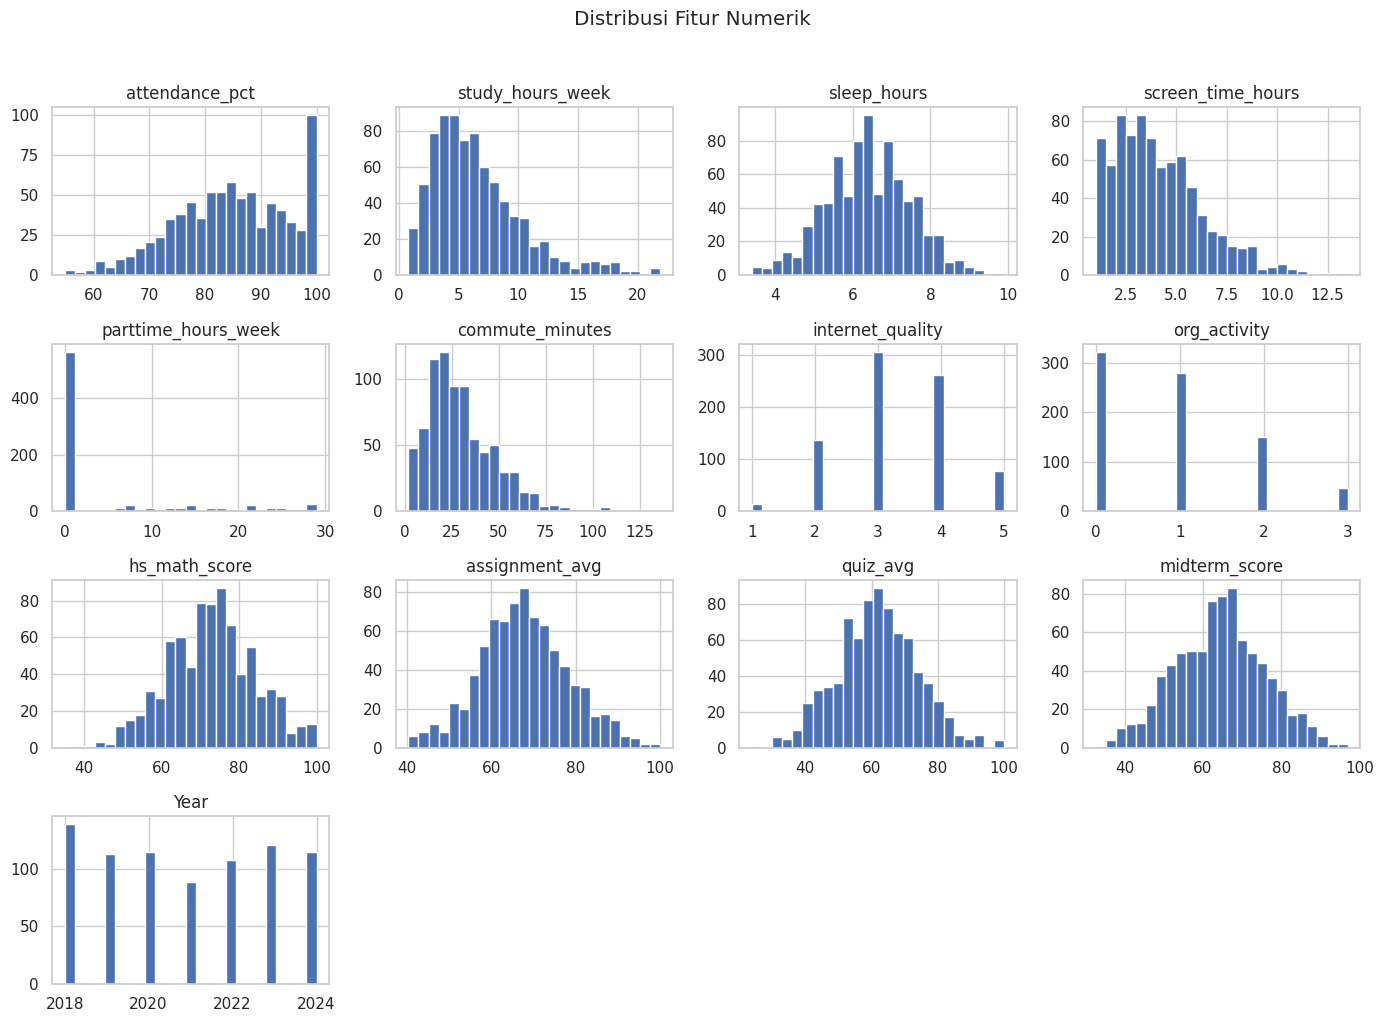

In [13]:
# Distribusi fitur numerik
df[num_cols_initial].hist(figsize=(14, 10), bins=25)
plt.suptitle("Distribusi Fitur Numerik", y=1.02)
plt.tight_layout()
plt.show()

# DATA CLEANING, TRANSFORMASI, DAN VISUALISASI LANJUTAN

## Tujuan
1. Membuat salinan data dan membersihkan duplikat.
2. Menangani missing values dan nilai invalid secara hati-hati.
3. Melakukan IQR capping pada fitur numerik yang dipilih setelah pemeriksaan.
4. Menyiapkan encoding, scaling, dan heatmap korelasi.
5. Membuat visualisasi dan insight awal.

In [14]:
# Buat salinan dan hapus duplikat
df_clean = df.copy()
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print("Duplikat yang dihapus:", before - len(df_clean))
print("Dimensi setelah hapus duplikat:", df_clean.shape)

Duplikat yang dihapus: 0
Dimensi setelah hapus duplikat: (800, 14)


In [15]:
# Normalisasi nilai teks yang jelas menandakan missing
# Nilai seperti '?' atau 'Unknown' diubah menjadi NaN.
missing_tokens = ["?", "??", "NA", "N/A", "na", "None", "null", "Null", "Unknown", "UNK", "-", "--", ""]
for col in df_clean.select_dtypes(include=["object"]).columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()
    df_clean[col] = df_clean[col].replace(missing_tokens, np.nan)

print("Missing values setelah normalisasi token:")
display(df_clean.isnull().sum().to_frame("jumlah_missing"))

Missing values setelah normalisasi token:


,jumlah_missing
attendance_pct,0
study_hours_week,0
sleep_hours,0
screen_time_hours,0
parttime_hours_week,0
commute_minutes,0
internet_quality,0
org_activity,0
hs_math_score,0
assignment_avg,0


In [16]:
# Validasi target
print("Nilai unik target:", df_clean[target_col].dropna().unique())

# Baris dengan target kosong tidak dapat digunakan untuk supervised learning.
before = len(df_clean)
df_clean = df_clean.dropna(subset=[target_col]).copy()
print("Baris dihapus karena target kosong:", before - len(df_clean))

# Jika target berupa teks, model tetap dapat mempelajari kelas tersebut.
# Jika target numerik, periksa bahwa kelasnya sesuai dokumentasi dataset.

Nilai unik target: [1 0]
Baris dihapus karena target kosong: 0


In [17]:
# Tangani nilai kosong pada fitur
# Imputasi median untuk numerik dan modus untuk kategorikal.
# Dilakukan sebagai persiapan; untuk modeling final, preprocessing akan dipasang
# di Pipeline agar parameter imputasi hanya dipelajari dari data training.
feature_cols = [c for c in df_clean.columns if c != target_col]
num_cols = df_clean[feature_cols].select_dtypes(include=np.number).columns.tolist()
cat_cols = df_clean[feature_cols].select_dtypes(exclude=np.number).columns.tolist()

for col in num_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

for col in cat_cols:
    mode = df_clean[col].mode(dropna=True)
    fill_value = mode.iloc[0] if not mode.empty else "Tidak diketahui"
    df_clean[col] = df_clean[col].fillna(fill_value)

print("Sisa missing values:")
display(df_clean.isnull().sum().to_frame("jumlah_missing"))

Sisa missing values:


,jumlah_missing
attendance_pct,0
study_hours_week,0
sleep_hours,0
screen_time_hours,0
parttime_hours_week,0
commute_minutes,0
internet_quality,0
org_activity,0
hs_math_score,0
assignment_avg,0


In [18]:
# IQR capping untuk fitur numerik
# Periksa hasil Week 1 dan sesuaikan daftar ini jika ada kolom yang secara domain
# tidak layak dicapping. Kolom target tidak pernah dicapping.
numeric_features = df_clean[feature_cols].select_dtypes(include=np.number).columns.tolist()

outlier_summary = []
for col in numeric_features:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count_before = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    df_clean[col] = df_clean[col].clip(lower=lower, upper=upper)
    outlier_summary.append({"kolom": col, "kandidat_outlier_awal": int(count_before),
                            "batas_bawah": lower, "batas_atas": upper})

display(pd.DataFrame(outlier_summary))
print("IQR capping diterapkan pada fitur numerik.")

,kolom,kandidat_outlier_awal,batas_bawah,batas_atas
0,attendance_pct,0,53.9250,116.1250
1,study_hours_week,36,-3.2375,15.2625
2,sleep_hours,1,3.3500,9.3500
3,screen_time_hours,15,-1.9500,9.6500
4,parttime_hours_week,88,-12.3750,20.6250
5,commute_minutes,24,-17.5000,74.5000
6,internet_quality,15,1.5000,5.5000
7,org_activity,48,-1.5000,2.5000
8,hs_math_score,3,42.5000,102.5000
9,assignment_avg,4,38.7625,95.6625


IQR capping diterapkan pada fitur numerik.


In [19]:
# Siapkan X dan y
X = df_clean.drop(columns=[target_col]).copy()
y = df_clean[target_col].copy()

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)
print("Fitur numerik:", num_cols)
print("Fitur kategorikal:", cat_cols)

Bentuk X: (800, 13)
Bentuk y: (800,)
Fitur numerik: ['attendance_pct', 'study_hours_week', 'sleep_hours', 'screen_time_hours', 'parttime_hours_week', 'commute_minutes', 'internet_quality', 'org_activity', 'hs_math_score', 'assignment_avg', 'quiz_avg', 'midterm_score', 'Year']
Fitur kategorikal: []


In [20]:
# One-Hot Encoding untuk eksplorasi
# Catatan: untuk evaluasi model, encoding akan dipasang di Pipeline setelah split.
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=False, dtype=int)
print("Dimensi fitur setelah encoding:", X_encoded.shape)
display(X_encoded.head())

Dimensi fitur setelah encoding: (800, 13)


,attendance_pct,study_hours_week,sleep_hours,screen_time_hours,parttime_hours_week,commute_minutes,internet_quality,org_activity,hs_math_score,assignment_avg,quiz_avg,midterm_score,Year
0,75.2,8.9,6.8,1.0,0.0,28.0,4.0,2.0,82.0,74.0,63.5,76.6,2024
1,74.3,6.7,4.2,1.7,0.0,37.0,3.0,0.0,100.0,64.2,62.4,63.1,2024
2,84.1,11.9,7.7,2.2,0.0,13.0,4.0,2.0,72.0,73.2,71.1,41.3,2024
3,74.4,4.8,6.6,3.7,6.0,15.0,3.0,1.0,61.0,42.3,49.5,76.0,2024
4,100.0,7.5,6.4,2.2,0.0,30.0,4.0,2.0,70.0,66.7,51.9,71.4,2024


In [21]:
# StandardScaler untuk eksplorasi
# Untuk menghindari data leakage pada evaluasi, scaler final akan dipasang
# dalam Pipeline Week 3. Di sini hanya contoh transformasi eksploratif.
from sklearn.preprocessing import StandardScaler

X_scaled_preview = X_encoded.copy()
scale_cols = X_scaled_preview.select_dtypes(include=np.number).columns.tolist()
scaler_preview = StandardScaler()
X_scaled_preview[scale_cols] = scaler_preview.fit_transform(X_scaled_preview[scale_cols])

print("Contoh fitur hasil scaling:")
display(X_scaled_preview.head())

Contoh fitur hasil scaling:


,attendance_pct,study_hours_week,sleep_hours,screen_time_hours,parttime_hours_week,commute_minutes,internet_quality,org_activity,hs_math_score,assignment_avg,quiz_avg,midterm_score,Year
0,-0.917239,0.694190,0.372496,-1.446678,-0.601393,-0.106614,0.744975,1.336320,0.824029,0.592443,0.150266,1.071002,1.484697
1,-1.004937,0.073133,-2.025867,-1.113171,-0.601393,0.413455,-0.353605,-1.036723,2.424841,-0.333037,0.059809,-0.111753,1.484697
2,-0.050012,1.541085,1.202698,-0.874951,-0.601393,-0.973397,0.744975,1.336320,-0.065311,0.516894,0.775247,-2.021682,1.484697
3,-0.995193,-0.463234,0.188006,-0.160292,0.184528,-0.857826,-0.353605,0.149798,-1.043585,-2.401203,-1.001013,1.018435,1.484697
4,1.499305,0.298972,0.003517,-0.874951,-0.601393,0.008957,0.744975,1.336320,-0.243179,-0.096945,-0.803651,0.615423,1.484697


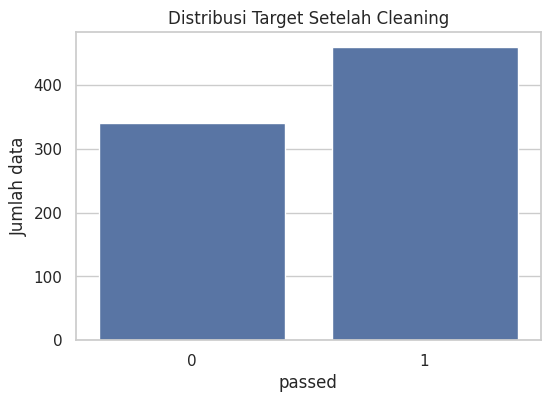

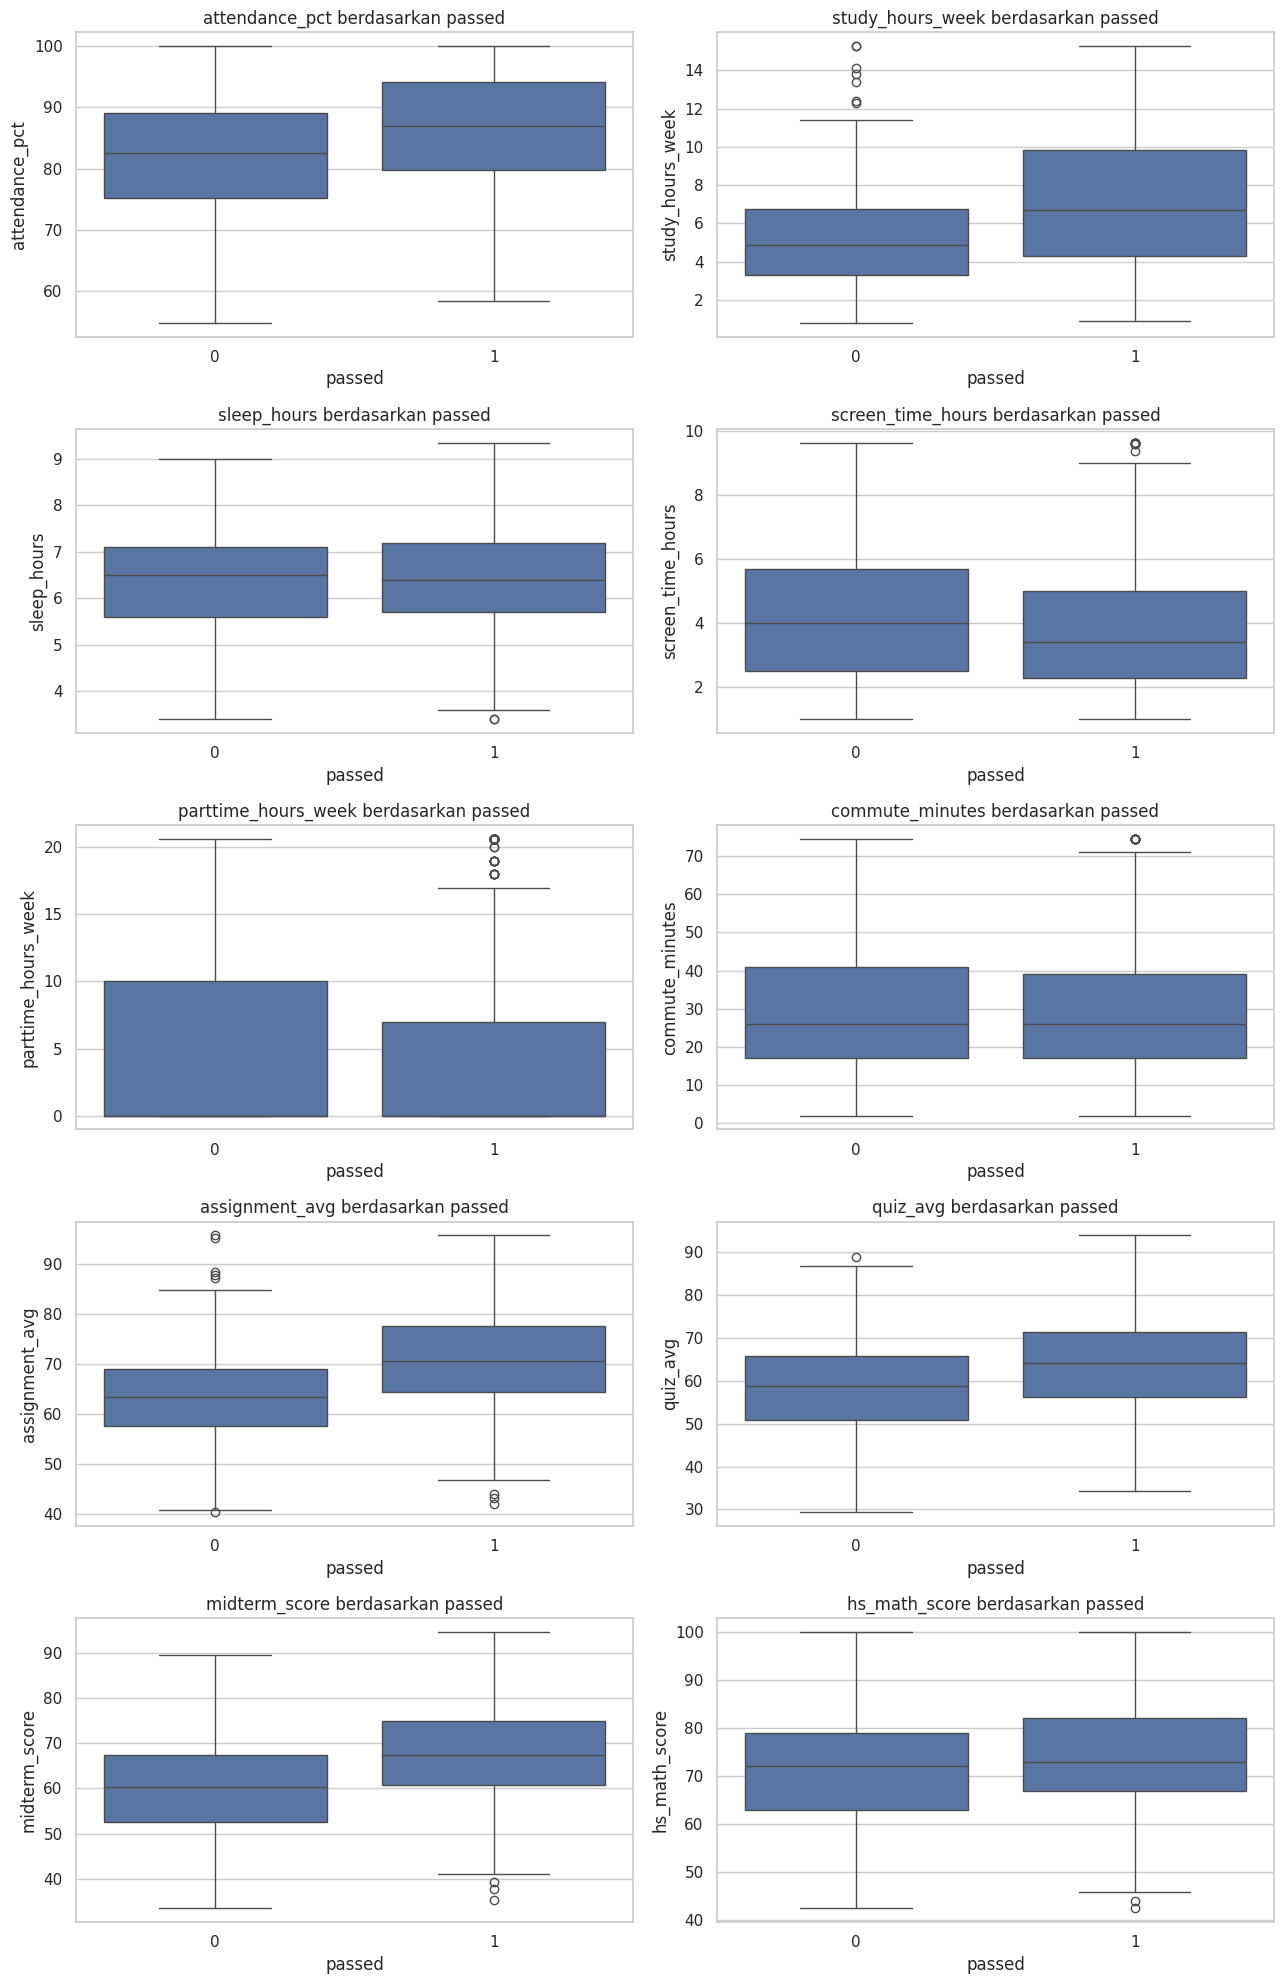

In [22]:
# Visualisasi target dan fitur utama
plt.figure(figsize=(6, 4))
sns.countplot(data=df_clean, x=target_col)
plt.title("Distribusi Target Setelah Cleaning")
plt.xlabel("passed")
plt.ylabel("Jumlah data")
plt.show()

important_numeric = [c for c in ["attendance_pct", "study_hours_week", "sleep_hours",
                                  "screen_time_hours", "parttime_hours_week",
                                  "commute_minutes", "assignment_avg", "quiz_avg",
                                  "midterm_score", "hs_math_score"] if c in df_clean.columns]

if important_numeric:
    ncols = 2
    nrows = int(np.ceil(len(important_numeric) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4*nrows))
    axes = np.array(axes).reshape(-1)
    for i, col in enumerate(important_numeric):
        sns.boxplot(data=df_clean, x=target_col, y=col, ax=axes[i])
        axes[i].set_title(f"{col} berdasarkan {target_col}")
    for j in range(len(important_numeric), len(axes)):
        fig.delaxes(axes[j])
    plt.tight_layout()
    plt.show()

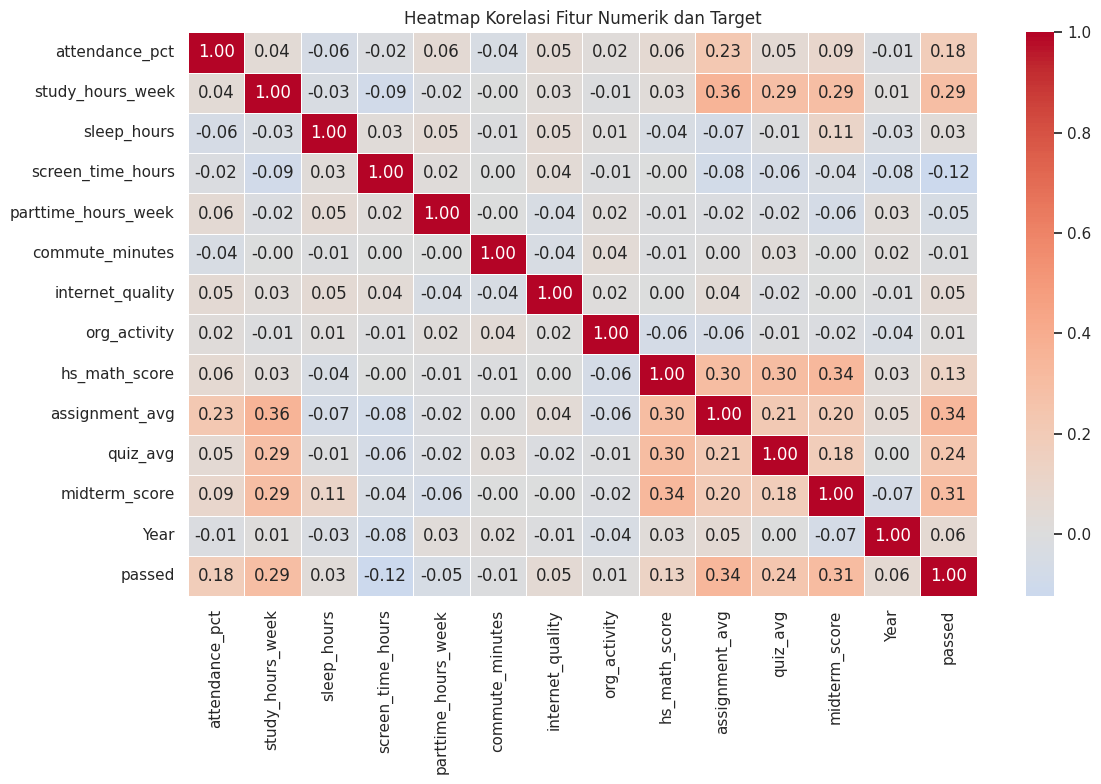

In [23]:
# Heatmap korelasi fitur numerik dan target (jika target numerik)
corr_df = df_clean.select_dtypes(include=np.number).copy()

if target_col not in corr_df.columns:
    # Encoding sementara untuk target kategorikal hanya untuk eksplorasi.
    # Kode ini bukan bukti kausalitas dan perlu interpretasi hati-hati.
    corr_df[target_col] = pd.factorize(df_clean[target_col])[0]

plt.figure(figsize=(12, 8))
sns.heatmap(corr_df.corr(numeric_only=True), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, linewidths=0.4)
plt.title("Heatmap Korelasi Fitur Numerik dan Target")
plt.tight_layout()
plt.show()

# TRAIN-TEST SPLIT, MACHINE LEARNING, DAN EVALUASI

## Tujuan
1. Membagi data menjadi 80% training dan 20% testing.
2. Membuat preprocessing di dalam Pipeline untuk mencegah data leakage.
3. Melatih dan membandingkan beberapa algoritma klasifikasi.
4. Mengevaluasi Accuracy, Precision, Recall, F1-score, dan Confusion Matrix.
5. Menentukan model terbaik berdasarkan metrik yang sesuai.

In [24]:
# Import library modeling
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

print("Library modeling siap.")

Library modeling siap.


In [25]:
# Definisikan fitur dan target dari data hasil cleaning
X = df_clean.drop(columns=[target_col]).copy()
y = df_clean[target_col].copy()

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

# Periksa kelas target
print("Kelas target:", y.value_counts(dropna=False).to_dict())

# Stratify digunakan jika setiap kelas memiliki minimal 2 contoh.
class_counts = y.value_counts()
use_stratify = y if len(class_counts) > 1 and class_counts.min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=use_stratify
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

Kelas target: {1: 460, 0: 340}
X_train: (640, 13)
X_test : (160, 13)
y_train: (640,)
y_test : (160,)


In [26]:
# Preprocessor
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols)
])

print("Preprocessor berhasil disiapkan.")

Preprocessor berhasil disiapkan.


In [27]:
# Tentukan model klasifikasi
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42,
                                            class_weight="balanced"),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Support Vector Machine": SVC(class_weight="balanced")
}

print("Model yang akan dibandingkan:", list(models.keys()))

Model yang akan dibandingkan: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'K-Nearest Neighbors', 'Support Vector Machine']


In [28]:
# Latih dan evaluasi semua model
results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    # Mendukung target biner maupun multiclass.
    average_type = "binary" if y.nunique() == 2 else "weighted"
    pos_label = 1 if 1 in list(y.unique()) else sorted(y.unique(), key=str)[-1]

    precision = precision_score(y_test, y_pred, average=average_type,
                                pos_label=pos_label if average_type == "binary" else None,
                                zero_division=0)
    recall = recall_score(y_test, y_pred, average=average_type,
                          pos_label=pos_label if average_type == "binary" else None,
                          zero_division=0)
    f1 = f1_score(y_test, y_pred, average=average_type,
                  pos_label=pos_label if average_type == "binary" else None,
                  zero_division=0)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })
    trained_models[name] = pipeline

df_results = pd.DataFrame(results).sort_values("F1-Score", ascending=False)
display(df_results.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
2,Random Forest,0.6562,0.6989,0.7065,0.7027
3,K-Nearest Neighbors,0.6375,0.6735,0.7174,0.6947
1,Decision Tree,0.6188,0.6598,0.6957,0.6772
0,Logistic Regression,0.6438,0.7108,0.6413,0.6743
4,Support Vector Machine,0.6438,0.7215,0.6196,0.6667


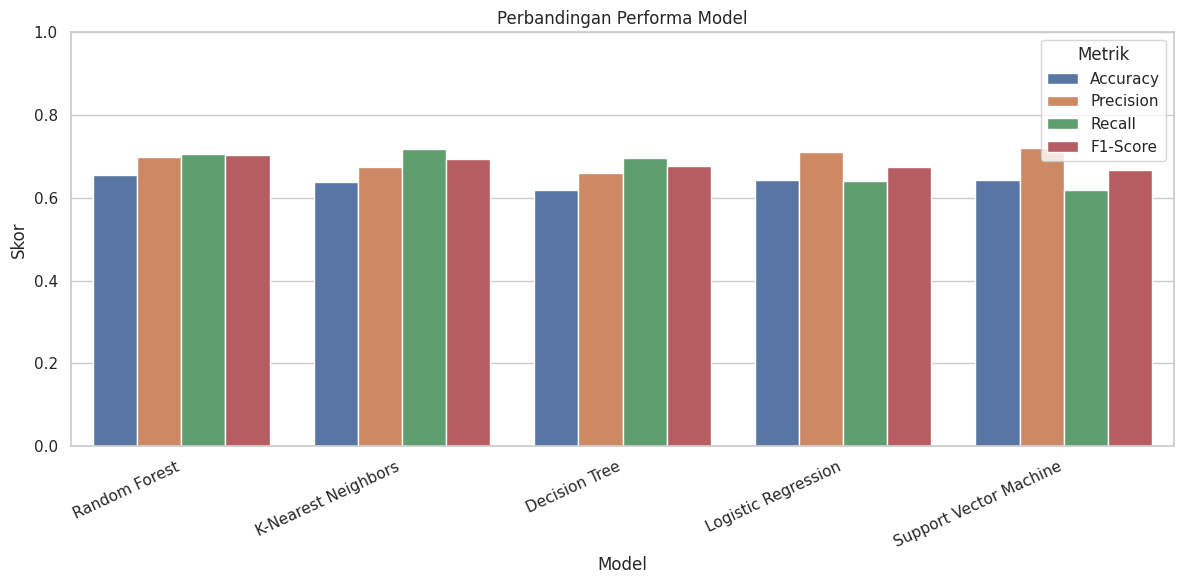

In [29]:
# Grafik perbandingan model
plot_results = df_results.melt(id_vars="Model", var_name="Metrik", value_name="Skor")
plt.figure(figsize=(12, 6))
sns.barplot(data=plot_results, x="Model", y="Skor", hue="Metrik")
plt.title("Perbandingan Performa Model")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [30]:
# Pilih model terbaik berdasarkan F1-score
best_model_name = df_results.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Model terbaik berdasarkan F1-score:", best_model_name)
print("\nClassification Report:")
print(classification_report(y_test, best_predictions, zero_division=0))

Model terbaik berdasarkan F1-score: Random Forest

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.59      0.59        68
           1       0.70      0.71      0.70        92

    accuracy                           0.66       160
   macro avg       0.65      0.65      0.65       160
weighted avg       0.66      0.66      0.66       160



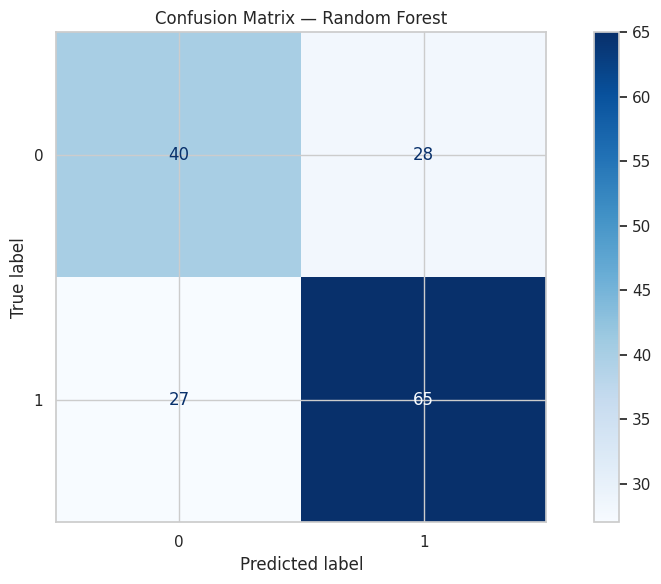

In [31]:
# Confusion Matrix
labels = sorted(y_test.unique(), key=str)
ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions, labels=labels, cmap="Blues", values_format="d"
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

In [32]:
# Kesimpulan metrik model terbaik
best_row = df_results.iloc[0]
print(f"Model terbaik: {best_row['Model']}")
print(f"Accuracy : {best_row['Accuracy']:.3f}")
print(f"Precision: {best_row['Precision']:.3f}")
print(f"Recall   : {best_row['Recall']:.3f}")
print(f"F1-Score : {best_row['F1-Score']:.3f}")

Model terbaik: Random Forest
Accuracy : 0.656
Precision: 0.699
Recall   : 0.707
F1-Score : 0.703


Mencoba model lain

Logistic Regression,
K-Nearest Neighbors (KNN),
Decision Tree

In [33]:

# Import library Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Library Machine Learning berhasil diimpor!")

Library Machine Learning berhasil diimpor!


In [34]:

# Menentukan fitur (X) dan target (y)
target_col = "passed"

X = df_clean.drop(columns=[target_col])
y = df_clean[target_col]

# Mengidentifikasi kolom numerik dan kategorikal
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

# Membagi data: 80% training dan 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing :", len(X_test))
print("Jumlah fitur        :", X.shape[1])

Jumlah data training: 640
Jumlah data testing : 160
Jumlah fitur        : 13


X berisi fitur mahasiswa yang digunakan untuk prediksi.



y berisi status passed yang ingin diprediksi.



test_size=0.2 berarti 20% data untuk pengujian.



random_state=42 membuat pembagian data konsisten saat dijalankan ulang.



stratify=y menjaga proporsi kelas target pada data training dan testing.

In [35]:

# Preprocessing untuk fitur numerik
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing untuk fitur kategorikal
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Menggabungkan preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, num_cols),
    ("cat", categorical_transformer, cat_cols)
])

print("Preprocessing berhasil dibuat!")


Preprocessing berhasil dibuat!


Penjelasan:
- SimpleImputer menangani nilai kosong jika masih ada.
- StandardScaler menyamakan skala fitur numerik, terutama bermanfaat untuk Logistic Regression dan KNN.
- OneHotEncoder mengubah fitur kategori menjadi representasi numerik.
- ColumnTransformer menerapkan proses berbeda untuk kolom numerik dan kategorikal.
Preprocessing berada di dalam Pipeline, sehingga parameter transformasi dipelajari dari data training, bukan dari data testing.

In [36]:

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    )
}

print("Model yang digunakan:")
for nama in models:
    print("-", nama)

Model yang digunakan:
- Logistic Regression
- KNN
- Decision Tree



models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    )
}

print("Model yang digunakan:")
for nama in models:
    print("-", nama)


In [37]:

results = []
trained_models = {}
predictions = {}

for name, model in models.items():

    # Menggabungkan preprocessing dan model
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Melatih model dengan data training
    pipeline.fit(X_train, y_train)

    # Memprediksi data testing
    y_pred = pipeline.predict(X_test)

    # Menghitung metrik evaluasi
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, pos_label=1, zero_division=0
        )
    })

    trained_models[name] = pipeline
    predictions[name] = y_pred

# Menampilkan hasil dalam tabel
df_results = pd.DataFrame(results)
df_results = df_results.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

display(df_results.round(4))


,Model,Accuracy,Precision,Recall,F1-Score
0,KNN,0.6375,0.6735,0.7174,0.6947
1,Decision Tree,0.6188,0.6598,0.6957,0.6772
2,Logistic Regression,0.6438,0.7108,0.6413,0.6743


Penjelasan metrik:
- Accuracy: persentase seluruh prediksi yang benar.
- Precision: dari data yang diprediksi sebagai kelas positif (passed = 1), berapa yang benar-benar positif.
- Recall: dari seluruh data aktual kelas positif, berapa yang berhasil ditemukan model.
- F1-Score: ukuran gabungan Precision dan Recall.
Kode ini mengasumsikan passed menggunakan kelas 0 dan 1. Pastikan arti kelas positif sesuai dokumentasi dataset kamu.

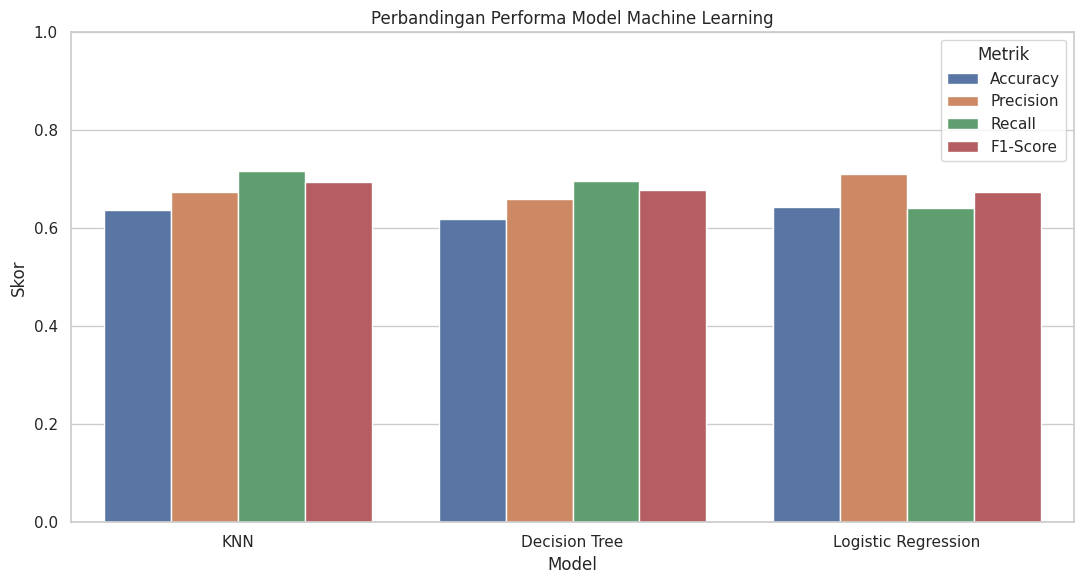

In [38]:

# Mengubah tabel agar mudah divisualisasikan
plot_results = df_results.melt(
    id_vars="Model",
    var_name="Metrik",
    value_name="Skor"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=plot_results,
    x="Model",
    y="Skor",
    hue="Metrik"
)

plt.title("Perbandingan Performa Model Machine Learning")
plt.xlabel("Model")
plt.ylabel("Skor")
plt.ylim(0, 1)
plt.legend(title="Metrik")
plt.tight_layout()
plt.show()


Model: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.65      0.61        68
           1       0.71      0.64      0.67        92

    accuracy                           0.64       160
   macro avg       0.64      0.64      0.64       160
weighted avg       0.65      0.64      0.65       160



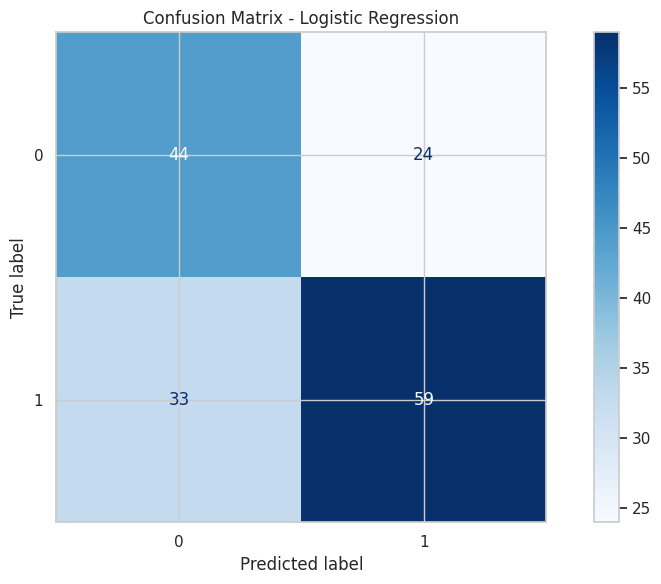


Model: KNN

Classification Report:
              precision    recall  f1-score   support

           0       0.58      0.53      0.55        68
           1       0.67      0.72      0.69        92

    accuracy                           0.64       160
   macro avg       0.63      0.62      0.62       160
weighted avg       0.63      0.64      0.63       160



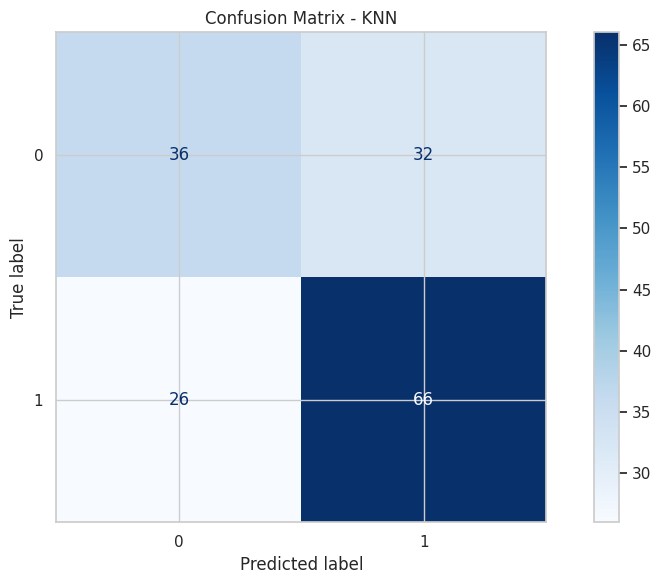


Model: Decision Tree

Classification Report:
              precision    recall  f1-score   support

           0       0.56      0.51      0.53        68
           1       0.66      0.70      0.68        92

    accuracy                           0.62       160
   macro avg       0.61      0.61      0.61       160
weighted avg       0.62      0.62      0.62       160



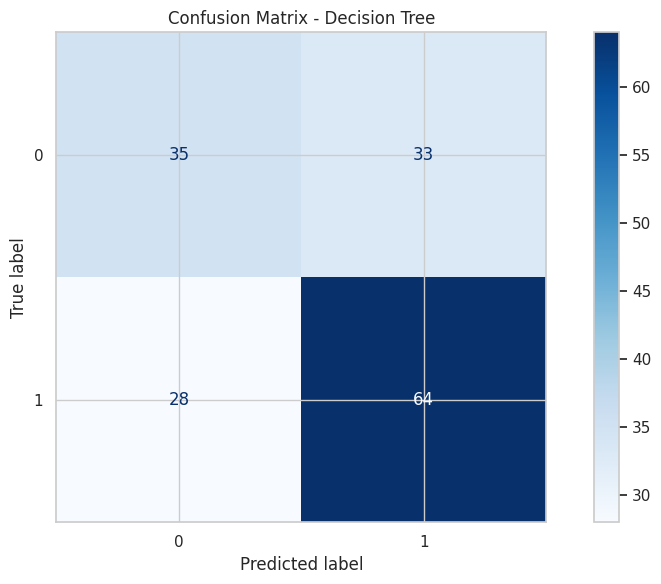

In [39]:

for name, y_pred in predictions.items():

    print("\nModel:", name)

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0, 1],
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

In [40]:

best_model_name = df_results.loc[0, "Model"]
best_model = trained_models[best_model_name]

print("MODEL TERBAIK BERDASARKAN F1-SCORE")
print("Nama model :", best_model_name)
print("Accuracy   :", round(df_results.loc[0, "Accuracy"], 4))
print("Precision  :", round(df_results.loc[0, "Precision"], 4))
print("Recall     :", round(df_results.loc[0, "Recall"], 4))
print("F1-Score   :", round(df_results.loc[0, "F1-Score"], 4))

MODEL TERBAIK BERDASARKAN F1-SCORE
Nama model : KNN
Accuracy   : 0.6375
Precision  : 0.6735
Recall     : 0.7174
F1-Score   : 0.6947


In [41]:

print("KESIMPULAN PROYEK DATA SCIENCE")
print("--------------------------------")
print("Dataset digunakan untuk memprediksi target passed.")
print("Jumlah data training:", len(X_train))
print("Jumlah data testing :", len(X_test))
print("Model terbaik berdasarkan F1-Score:", best_model_name)

print("\nPerbandingan hasil:")
display(df_results.round(4))

print(
    "\nKesimpulan harus mempertimbangkan metrik evaluasi, "
    "confusion matrix, definisi target, dan keterbatasan dataset."
)

KESIMPULAN PROYEK DATA SCIENCE
--------------------------------
Dataset digunakan untuk memprediksi target passed.
Jumlah data training: 640
Jumlah data testing : 160
Model terbaik berdasarkan F1-Score: KNN

Perbandingan hasil:


,Model,Accuracy,Precision,Recall,F1-Score
0,KNN,0.6375,0.6735,0.7174,0.6947
1,Decision Tree,0.6188,0.6598,0.6957,0.6772
2,Logistic Regression,0.6438,0.7108,0.6413,0.6743



Kesimpulan harus mempertimbangkan metrik evaluasi, confusion matrix, definisi target, dan keterbatasan dataset.


mencari rata rata yang lebih dari 0.80

In [42]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
import pandas as pd

models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, class_weight="balanced"),
        {
            "model__C": [0.01, 0.1, 1, 10, 100]
        }
    ),

    "KNN": (
        KNeighborsClassifier(),
        {
            "model__n_neighbors": [3, 5, 7, 9, 11, 15],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        }
    ),

    "Decision Tree": (
        DecisionTreeClassifier(
            class_weight="balanced",
            random_state=42
        ),
        {
            "model__max_depth": [3, 5, 7, 10, None],
            "model__min_samples_leaf": [2, 5, 10, 15],
            "model__criterion": ["gini", "entropy"]
        }
    )
}

hasil = []

for nama, (model, parameter) in models.items():
    pipe = Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("model", model)
    ])

    pencarian = GridSearchCV(
        estimator=pipe,
        param_grid=parameter,
        scoring="precision",
        cv=5,
        n_jobs=-1
    )

    pencarian.fit(X_train, y_train)

    model_terbaik = pencarian.best_estimator_
    prediksi = model_terbaik.predict(X_test)

    accuracy = accuracy_score(y_test, prediksi)
    precision = precision_score(
        y_test, prediksi, zero_division=0
    )
    recall = recall_score(
        y_test, prediksi, zero_division=0
    )
    f1 = f1_score(y_test, prediksi, zero_division=0)

    hasil.append({
        "Model": nama,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "Parameter Terbaik": pencarian.best_params_
    })

    print(f"\nModel: {nama}")
    print("Parameter terbaik:", pencarian.best_params_)
    print("Accuracy:", round(accuracy, 3))
    print("Precision:", round(precision, 3))
    print("Recall:", round(recall, 3))
    print("F1-Score:", round(f1, 3))

df_hasil = pd.DataFrame(hasil)
display(
    df_hasil.sort_values(
        by=["Precision", "Accuracy"],
        ascending=False
    ).reset_index(drop=True)
)


Model: Logistic Regression
Parameter terbaik: {'model__C': 0.01}
Accuracy: 0.65
Precision: 0.72
Recall: 0.641
F1-Score: 0.678

Model: KNN
Parameter terbaik: {'model__n_neighbors': 15, 'model__p': 2, 'model__weights': 'uniform'}
Accuracy: 0.637
Precision: 0.673
Recall: 0.717
F1-Score: 0.695

Model: Decision Tree
Parameter terbaik: {'model__criterion': 'entropy', 'model__max_depth': 3, 'model__min_samples_leaf': 5}
Accuracy: 0.6
Precision: 0.684
Recall: 0.565
F1-Score: 0.619


,Model,Accuracy,Precision,Recall,F1-Score,Parameter Terbaik
0,Logistic Regression,0.6500,0.719512,0.641304,0.678161,{'model__C': 0.01}
1,Decision Tree,0.6000,0.684211,0.565217,0.619048,"{'model__criterion': 'entropy', 'model__max_de..."
2,KNN,0.6375,0.673469,0.717391,0.694737,"{'model__n_neighbors': 15, 'model__p': 2, 'mod..."
